# **1. Introduction**

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm used for classification and regression.

In regression, KNN predicts a continuous value by calculating the average target values of its nearest neighbors.

In this project, I use KNN Regression to predict medical insurance charges based on personal and health-related features.

# **2. Import Libraries**

Import the required libraries for data manipulation, visualization, preprocessing, model training, cross-validation, and evaluation.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# **3. Load Dataset**

Load the Medical Insurance Cost dataset downloaded from Kaggle.

The dataset contains personal information and medical insurance charges. We will use these features to predict insurance costs.

In [31]:
# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Data Science Projeccts/Algorithm/Medical-Cost-Charges/insurance.csv")

# Display the first five rows
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# **4. Dataset Overview**

Use shape to determine the number of rows and columns, info() to inspect data types, and isnull().sum() to check for missing values.

In [32]:
# Display the dataset dimensions
print("Dataset Shape:", df.shape)


Dataset Shape: (1338, 7)


In [33]:

# Display column information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [34]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


# **5. Statistical Summary**

Use describe() to examine the statistical properties of numerical columns, including mean, standard deviation, minimum, maximum, and quartiles.

In [35]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


# **6. Check Duplicate Records**

Check whether the dataset contains duplicate rows.

Duplicate records may affect the analysis, so we inspect them before proceeding.

In [36]:

print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 1


In [37]:
# Display duplicate rows
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [38]:
# Display all rows involved in duplication
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [39]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Duplicate Rows After Removal:", df.duplicated().sum())

Duplicate Rows After Removal: 0


# **7. Explore Categorical Features**

The dataset contains categorical features such as sex, smoker, and region.

Use value_counts() to examine the number of observations in each category.

In [40]:
# Display the distribution of categorical columns
for column in ["sex", "smoker", "region"]:
    print(f"\n{column.upper()} Distribution:")
    print(df[column].value_counts())


SEX Distribution:
sex
male      675
female    662
Name: count, dtype: int64

SMOKER Distribution:
smoker
no     1063
yes     274
Name: count, dtype: int64

REGION Distribution:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


# **8. Distribution of Insurance Charges**

The charges column is our target variable.

Plot its distribution to understand how insurance charges are spread across the dataset and whether the distribution is skewed.

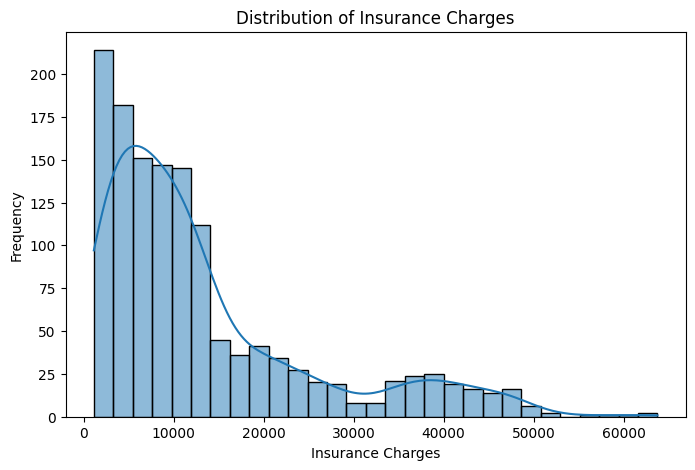

In [41]:
# Plot the distribution of insurance charges
plt.figure(figsize=(8, 5))

sns.histplot(df["charges"], kde=True)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")
plt.show()

# **9. Analyze Numerical Features**

Visualize the distributions of age, BMI, and the number of children.

These plots help us understand the spread and frequency of values in the numerical features.

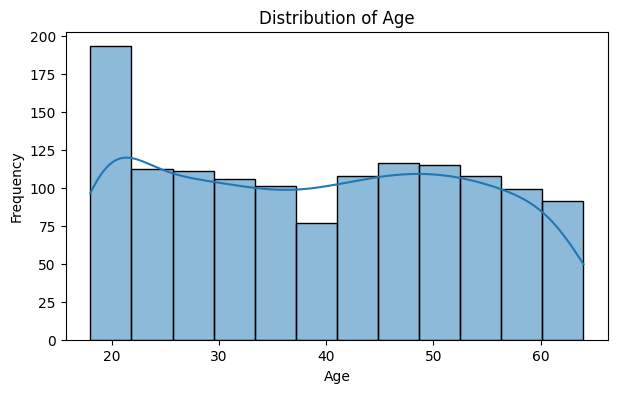

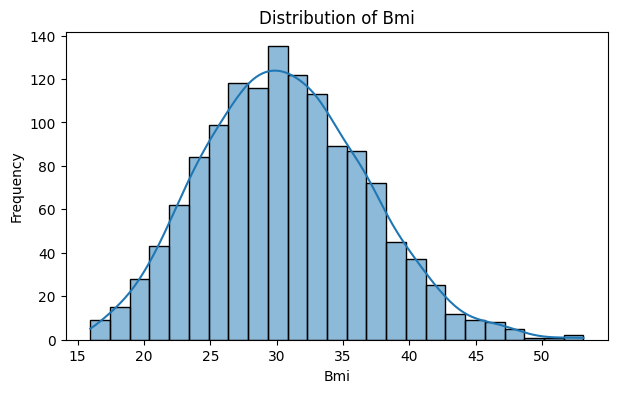

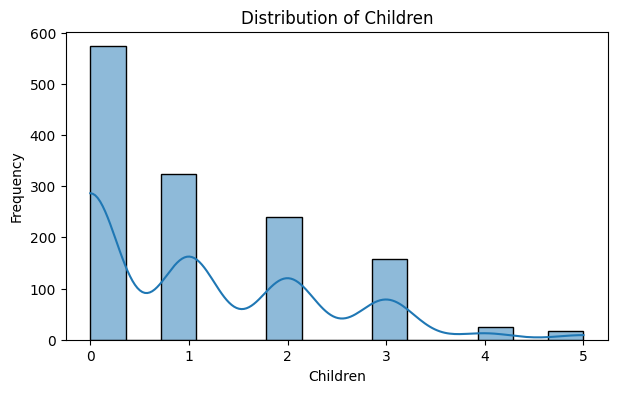

In [42]:
# Plot distributions of numerical features
numerical_columns = ["age", "bmi", "children"]

for column in numerical_columns:
    plt.figure(figsize=(7, 4))

    sns.histplot(df[column], kde=True)

    plt.title(f"Distribution of {column.capitalize()}")
    plt.xlabel(column.capitalize())
    plt.ylabel("Frequency")

    plt.show()

# **10. Smoking Status vs Insurance Charges**

Compare insurance charges for smokers and non-smokers using a boxplot.

This helps us investigate how insurance charges differ between these two groups.

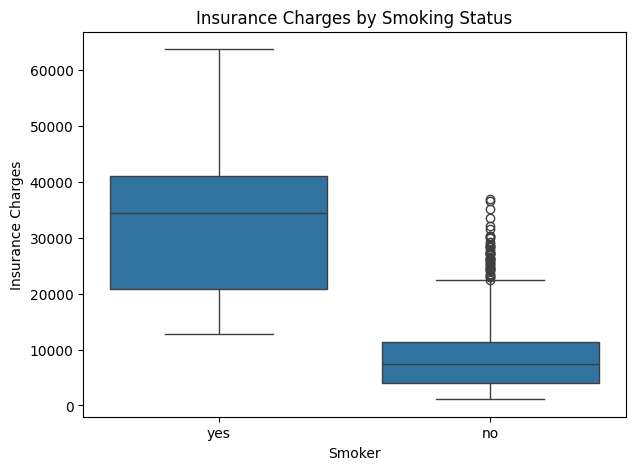

In [43]:
# Compare insurance charges by smoking status
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")

plt.show()

# **11. Age vs Insurance Charges**

Use a scatter plot to examine the relationship between age and insurance charges.

Each point represents one observation in the dataset.

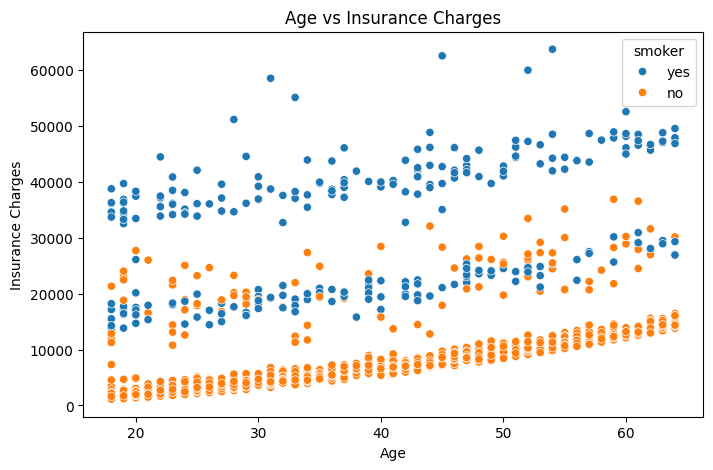

In [44]:
# Plot age against insurance charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.show()

**Interpretation** : The scatter plot shows a positive relationship between age and insurance charges, meaning charges generally increase as age increases. Smokers have considerably higher insurance charges than non-smokers across almost all age groups. Non-smokers mostly have charges below 15,000, while smokers frequently have charges above 30,000, with some exceeding 60,000. This indicates that smoking has a strong impact on insurance costs, while age also contributes to increasing charges.

# **12. BMI vs Insurance Charges**

Visualize the relationship between BMI and insurance charges.

Color the observations according to smoking status to explore whether the relationship appears different between smokers and non-smokers.

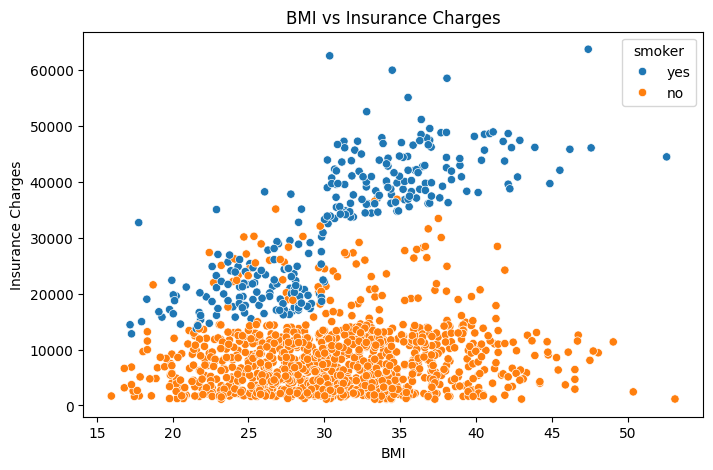

In [45]:
# Plot BMI against insurance charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.show()

# **13. Separate Features and Target**

The features (X) contain the information used to predict insurance charges.

The target (y) is the charges column.

I will remove charges from the input features because it is the value the model must predict.

In [46]:
# Separate input features and target variable
X = df.drop("charges", axis=1)
y = df["charges"]

# Display the input features
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


# **14. Identify Feature Types**

KNN requires numerical inputs because it calculates distances between observations.

I will standardize numerical features and encode categorical features using One-Hot Encoding.

In [47]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['age', 'bmi', 'children']
Categorical Features: ['sex', 'smoker', 'region']


# **15. Train-Test Split**

Split the dataset into training and testing sets.

- Training set: Used to train the model and select the best K.
- Testing set: Used for final evaluation on unseen observations.

We use 80% of the data for training and 20% for testing.

In [48]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1069, 6)
X_test: (268, 6)
y_train: (1069,)
y_test: (268,)


# **16. Feature Preprocessing**

KNN uses distances to identify the nearest observations, so feature scaling is important.

I will use ColumnTransformer to apply different preprocessing methods:

1. StandardScaler: Standardizes numerical features.
2. OneHotEncoder: Converts categorical features into numerical columns.

The preprocessing will be fitted on the training data within the Pipeline and applied to the testing data.

In [49]:
# Define preprocessing for numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'bmi', 'children']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sex', 'smoker', 'region'])])

# **17. Build the KNN Regression Pipeline**

Create a Pipeline that combines feature preprocessing with KNN Regression.

The pipeline ensures that the same preprocessing steps are applied consistently during cross-validation, training, and prediction.

In [50]:
# Create the KNN regression pipeline
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsRegressor())
])

knn_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('knn', KNeighborsRegressor())])

# **18. Hyperparameter Tuning Using Cross-Validation**

The value of K determines how many nearest neighbors contribute to a prediction.

A small K can make predictions sensitive to individual observations, while a large K may smooth out important local patterns.

I will use GridSearchCV with 5-fold cross-validation to test different K values.

The negative mean squared error scoring option allows GridSearchCV to select the K with the lowest average validation MSE.

In [51]:
# Define 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the K values to test
param_grid = {
    "knn__n_neighbors": list(range(2, 26))
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

# Train and compare models using cross-validation
grid_search.fit(X_train, y_train)

# Display the best K and its cross-validation MSE
print("Best K:", grid_search.best_params_["knn__n_neighbors"])

print(
    "Best Cross-Validation MSE:",
    -grid_search.best_score_
)

Best K: 5
Best Cross-Validation MSE: 37301133.06380714


# **19. Compare Different K Values**

Display the cross-validation results for each tested K.

I will convert the negative MSE scores into positive values to make them easier to interpret. A lower MSE indicates better validation performance.

In [52]:
# Convert cross-validation results into a DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

# Select relevant columns
cv_results = cv_results[
    [
        "param_knn__n_neighbors",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

# Convert negative MSE to positive MSE
cv_results["MSE"] = (
    -cv_results["mean_test_score"]
)

# Rename columns
cv_results = cv_results.rename(
    columns={
        "param_knn__n_neighbors": "K",
        "std_test_score": "Standard Deviation of Negative MSE"
    }
)

# Display the results
cv_results[
    ["K", "MSE"]
]

,K,MSE
0,2,4.064300e+07
1,3,3.780544e+07
2,4,3.817701e+07
3,5,3.730113e+07
4,6,3.796597e+07
5,7,3.849806e+07
6,8,4.027963e+07
7,9,4.062020e+07
8,10,4.146518e+07
9,11,4.248273e+07


# **20. Visualize K Selection**

Plot K against the mean cross-validation MSE.

The K value with the lowest mean cross-validation MSE is selected by GridSearchCV.

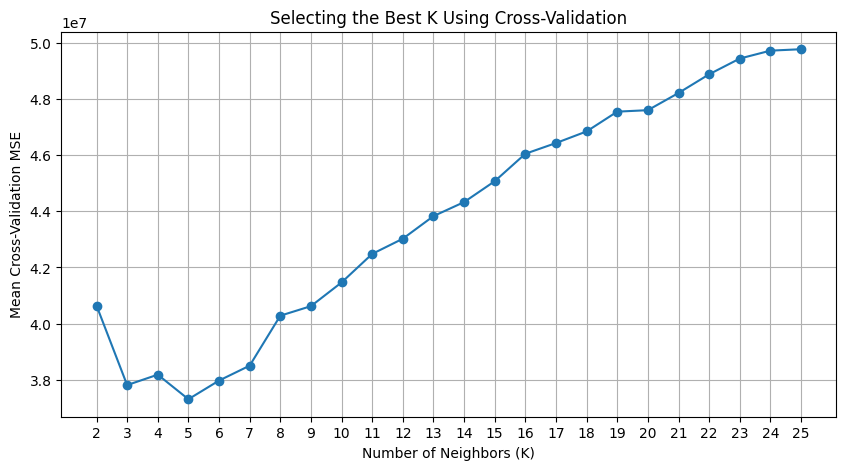

In [53]:
plt.figure(figsize=(10, 5))

plt.plot(
    cv_results["K"].astype(int),
    cv_results["MSE"],
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("Selecting the Best K Using Cross-Validation")

plt.xticks(cv_results["K"].astype(int))
plt.grid(True)
plt.show()

# **21. Select the Best KNN Model**

Retrieve the best estimator selected by GridSearchCV.

It contains the preprocessing steps and the KNN Regressor with the selected value of K.

In [54]:
# Retrieve the best pipeline
best_knn = grid_search.best_estimator_

print("Best K:", best_knn.named_steps["knn"].n_neighbors)

print("\nBest Model:")
print(best_knn)

Best K: 5

Best Model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('knn', KNeighborsRegressor())])


# **22. Make Predictions**

Use the selected KNN model to predict insurance charges for the testing data.

The pipeline automatically encodes categorical features and standardizes numerical features before making predictions.

In [55]:
# Predict insurance charges for the testing set
y_pred = best_knn.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Charges": y_test.to_numpy(),
    "Predicted Charges": y_pred
})

results.head(10)

,Actual Charges,Predicted Charges
0,8688.85885,9943.631010
1,5708.86700,7790.933946
2,11436.73815,16508.519848
3,38746.35510,31697.395948
4,4463.20510,5320.402980
5,9304.70190,8206.770640
6,38511.62830,35057.443506
7,2150.46900,2266.262000
8,7345.72660,8280.884760
9,10264.44210,9665.528660


# **23. Model Evaluation**

Evaluate the model using four regression metrics:

- Mean Absolute Error (MAE): Average absolute difference between actual and predicted values.
- Mean Squared Error (MSE): Average squared prediction error.
- Root Mean Squared Error (RMSE): Square root of MSE, expressed in the same units as the target.
- R² Score: Measures how much variation in the target is explained by the model relative to predicting the test-set mean.

Lower MAE, MSE, and RMSE indicate smaller prediction errors. A higher R² generally indicates better performance.

In [56]:
# Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display the evaluation results

print("Mean Absolute Error : ", mae)
print("Mean Squared Error : ", mse)
print("Root Mean Squared Error : ", rmse)
print("R² Score : ", r2)

Mean Absolute Error :  3806.5823452499994
Mean Squared Error :  40134156.721553944
Root Mean Squared Error :  6335.152462376414
R² Score :  0.7815900284380415


# **24. Actual vs Predicted Values**

Create a scatter plot comparing actual insurance charges with predicted charges.

The diagonal reference line represents perfect predictions. Points closer to this line indicate smaller prediction errors.

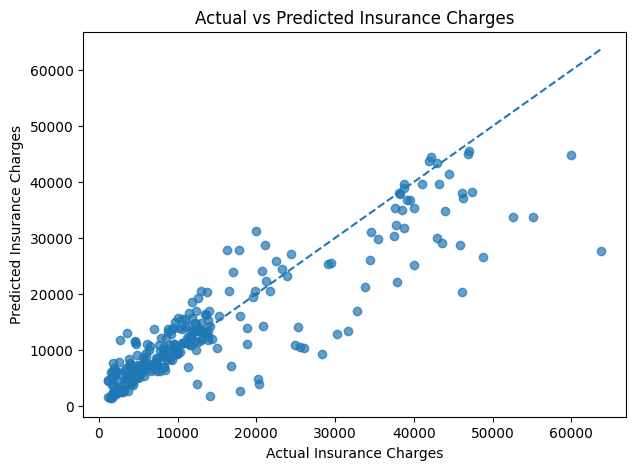

In [57]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

# **25. Residual Analysis**

A residual is the difference between an actual value and its predicted value.

Residual = Actual Value − Predicted Value

Plot the residuals against predicted charges to examine prediction errors.

A residual plot can help reveal systematic errors or patterns that the model may not capture.

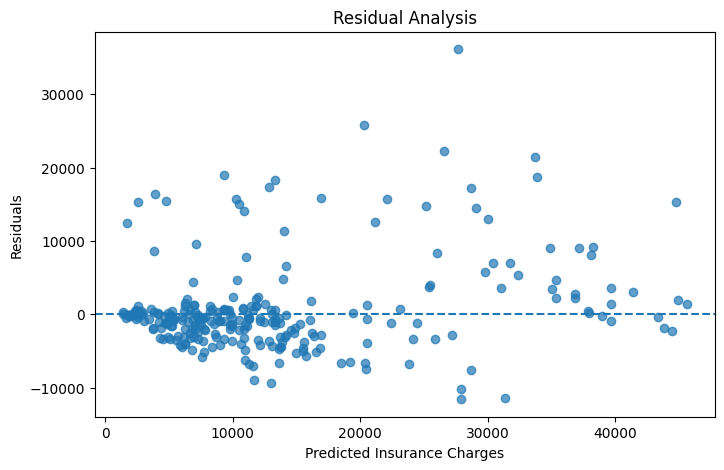

In [58]:
# Calculate residuals
residuals = y_test.to_numpy() - y_pred

# Plot residuals against predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)

# Reference line for zero residual
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()

# **27. Conclusion**

In this project, I implemented K-Nearest Neighbors Regression using the Medical Insurance Cost dataset from Kaggle.

I performed exploratory data analysis, examined the relationships between features and insurance charges, and prepared the numerical and categorical features for model training.

I used StandardScaler and OneHotEncoder through a ColumnTransformer and Pipeline to preprocess the features correctly.

I applied 5-fold cross-validation with GridSearchCV to select the best value of K based on mean squared error.

Finally, I evaluated the selected model using MAE, MSE, RMSE, and R² score, along with actual-versus-predicted and residual plots.

This project helped me understand how KNN Regression works, why feature scaling matters, and how cross-validation can be used for hyperparameter tuning.